# Hello, KAN!

### Kolmogorov-Arnold representation theorem

Kolmogorov-Arnold representation theorem states that if $f$ is a multivariate continuous function
on a bounded domain, then it can be written as a finite composition of continuous functions of a
single variable and the binary operation of addition. More specifically, for a smooth $f : [0,1]^n \to \mathbb{R}$,


$$f(x) = f(x_1,...,x_n)=\sum_{q=1}^{2n+1}\Phi_q(\sum_{p=1}^n \phi_{q,p}(x_p))$$

where $\phi_{q,p}:[0,1]\to\mathbb{R}$ and $\Phi_q:\mathbb{R}\to\mathbb{R}$. In a sense, they showed that the only true multivariate function is addition, since every other function can be written using univariate functions and sum. However, this 2-Layer width-$(2n+1)$ Kolmogorov-Arnold representation may not be smooth due to its limited expressive power. We augment its expressive power by generalizing it to arbitrary depths and widths.

### Kolmogorov-Arnold Network (KAN)

The Kolmogorov-Arnold representation can be written in matrix form

$$f(x)={\bf \Phi}_{\rm out}\circ{\bf \Phi}_{\rm in}\circ {\bf x}$$

where 

$${\bf \Phi}_{\rm in}= \begin{pmatrix} \phi_{1,1}(\cdot) & \cdots & \phi_{1,n}(\cdot) \\ \vdots & & \vdots \\ \phi_{2n+1,1}(\cdot) & \cdots & \phi_{2n+1,n}(\cdot) \end{pmatrix},\quad {\bf \Phi}_{\rm out}=\begin{pmatrix} \Phi_1(\cdot) & \cdots & \Phi_{2n+1}(\cdot)\end{pmatrix}$$

We notice that both ${\bf \Phi}_{\rm in}$ and ${\bf \Phi}_{\rm out}$ are special cases of the following function matrix ${\bf \Phi}$ (with $n_{\rm in}$ inputs, and $n_{\rm out}$ outputs), we call a Kolmogorov-Arnold layer:

$${\bf \Phi}= \begin{pmatrix} \phi_{1,1}(\cdot) & \cdots & \phi_{1,n_{\rm in}}(\cdot) \\ \vdots & & \vdots \\ \phi_{n_{\rm out},1}(\cdot) & \cdots & \phi_{n_{\rm out},n_{\rm in}}(\cdot) \end{pmatrix}$$

${\bf \Phi}_{\rm in}$ corresponds to $n_{\rm in}=n, n_{\rm out}=2n+1$, and ${\bf \Phi}_{\rm out}$ corresponds to $n_{\rm in}=2n+1, n_{\rm out}=1$.

After defining the layer, we can construct a Kolmogorov-Arnold network simply by stacking layers! Let's say we have $L$ layers, with the $l^{\rm th}$ layer ${\bf \Phi}_l$ have shape $(n_{l+1}, n_{l})$. Then the whole network is

$${\rm KAN}({\bf x})={\bf \Phi}_{L-1}\circ\cdots \circ{\bf \Phi}_1\circ{\bf \Phi}_0\circ {\bf x}$$

In constrast, a Multi-Layer Perceptron is interleaved by linear layers ${\bf W}_l$ and nonlinearities $\sigma$:

$${\rm MLP}({\bf x})={\bf W}_{L-1}\circ\sigma\circ\cdots\circ {\bf W}_1\circ\sigma\circ {\bf W}_0\circ {\bf x}$$

A KAN can be easily visualized. (1) A KAN is simply stack of KAN layers. (2) Each KAN layer can be visualized as a fully-connected layer, with a 1D function placed on each edge. Let's see an example below.

### Get started with KANs

Initialize KAN

In [1]:
import torch
from xkan import KANNetwork, create_dataset, fit
from xkan.interp import prune, refine
from xkan.symbolic import auto_symbolic, fix_symbolic, symbolic_formula
from xkan.utils import ex_round
from xkan.viz import plot

torch.set_default_dtype(torch.float64)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

# create a KAN: 2D inputs, 1D output, and 5 hidden neurons. cubic spline (k=3), 3 grid intervals (grid=3).
model = KANNetwork([2, 5, 1], grid=3, k=3, seed=42, device=device)

cuda


Create dataset

In [2]:
# create dataset f(x,y) = exp(sin(pi*x)+y^2): training and test sets, inputs under 'x', labels under 'y'
f = lambda x: torch.exp(torch.sin(torch.pi*x[:,[0]]) + x[:,[1]]**2)
train, test = create_dataset(f, n_var=2, device=device)
train['x'].shape, train['y'].shape

(torch.Size([1000, 2]), torch.Size([1000, 1]))

Plot KAN at initialization

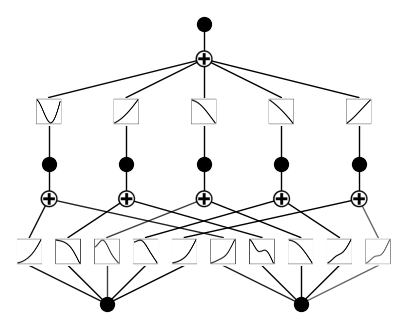

In [3]:
# plot KAN at initialization (the curves over the training inputs)
plot(model, train['x']);

Train KAN with sparsity regularization

In [4]:
# train the model (LBFGS, with sparsity regularization)
history = fit(model, train, test, steps=50, lamb=0.001)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

train RMSE 0.019086306692000257 test RMSE 0.018765709598382724


Plot trained KAN

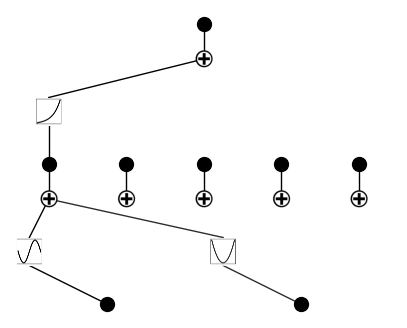

In [5]:
plot(model, train['x']);

Prune KAN and replot

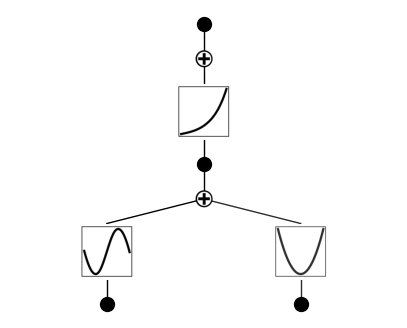

In [6]:
model = prune(model, train['x'])
plot(model, train['x']);

Continue training and replot

In [7]:
history = fit(model, train, test, steps=50)
print('train RMSE', history['train/y'][-1] ** 0.5)

train RMSE 0.017711292066264282


In [8]:
model = refine(model, 10, train['x'])

In [9]:
history = fit(model, train, test, steps=50)
print('train RMSE', history['train/y'][-1] ** 0.5)

train RMSE 0.0004615378798966142


Automatically or manually set activation functions to be symbolic

In [10]:
mode = "auto" # "manual"

if mode == "manual":
    # manual mode
    fix_symbolic(model, 0, 0, 0, 'sin', train['x'])
    fix_symbolic(model, 0, 1, 0, 'x^2', train['x'])
    fix_symbolic(model, 1, 0, 0, 'exp', train['x'])
elif mode == "auto":
    # automatic mode
    lib = ['x','x^2','x^3','x^4','exp','log','sqrt','tanh','sin','abs']
    auto_symbolic(model, train['x'], lib=lib)

fixing (0,0,0) with sin, r2=0.9999999157504531, c=2
fixing (0,1,0) with x^2, r2=0.9999999837067141, c=2
fixing (1,0,0) with exp, r2=0.9999999861152318, c=2


Continue training till machine precision

In [11]:
history = fit(model, train, test, steps=50)
print('train RMSE', history['train/y'][-1] ** 0.5)

train RMSE 2.4111120125825076e-15


Obtain the symbolic formula

In [12]:
ex_round(symbolic_formula(model)[0][0], 4)

1.0*exp(1.00168954931732*x_2**2 + 1.0*sin(3.1416*x_1))